In [ ]:

!pip -q install medmnist scikit-learn matplotlib seaborn


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import models, transforms

import medmnist
from medmnist import ChestMNIST

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, f1_score

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


In [ ]:

# Image transformations
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Download datasets
train_dataset = ChestMNIST(
    split="train",
    download=True,
    transform=transform
)

val_dataset = ChestMNIST(
    split="val",
    download=True,
    transform=transform
)

test_dataset = ChestMNIST(
    split="test",
    download=True,
    transform=transform
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Class names
class_names = list(train_dataset.info["label"].values())

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)


Train samples: 78468
Validation samples: 11219
Test samples: 22433
Number of classes: 14
Classes: ['atelectasis', 'cardiomegaly', 'effusion', 'infiltration', 'mass', 'nodule', 'pneumonia', 'pneumothorax', 'consolidation', 'edema', 'emphysema', 'fibrosis', 'pleural', 'hernia']


In [ ]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)


Image batch shape: torch.Size([32, 1, 128, 128])
Label batch shape: torch.Size([32, 14])
Image dtype: torch.float32
Label dtype: torch.int64


In [ ]:

# Load pretrained ResNet18
resnet_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Change first convolution layer: 3 channels -> 1 channel
original_conv = resnet_model.conv1

resnet_model.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)

# Initialize new convolution weights using RGB weight average
with torch.no_grad():
    resnet_model.conv1.weight.copy_(
        original_conv.weight.mean(dim=1, keepdim=True)
    )

# Change final classification layer: 1000 classes -> 14 classes
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    14
)

# Move model to GPU
resnet_model = resnet_model.to(device)

# Check model
print(resnet_model)
print("\nTotal parameters:",
      sum(p.numel() for p in resnet_model.parameters()))

print("Output layer:", resnet_model.fc)


ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [ ]:

# Calculate positive weights from training labels
train_labels = torch.tensor(
    train_dataset.labels,
    dtype=torch.float32
)

positive_counts = train_labels.sum(dim=0)
negative_counts = len(train_dataset) - positive_counts

pos_weights = negative_counts / positive_counts.clamp(min=1)

# Limit extreme weights
pos_weights = torch.clamp(pos_weights, max=50.0)

pos_weights = pos_weights.to(device)

# Loss function
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights
)

# Optimizer
optimizer = optim.Adam(
    resnet_model.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Positive weights:", pos_weights)


Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Positive weights: tensor([ 8.8134, 39.2400,  7.4730,  4.6395, 18.6760, 16.9355, 50.0000, 20.1789,
        23.0478, 45.4308, 42.6176, 50.0000, 33.4309, 50.0000], device='cuda:0')


In [ ]:

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.float().to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.float().to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

    return total_loss / len(loader)


print("Training and validation functions are ready!")


Training and validation functions are ready!


In [ ]:

num_epochs = 5

resnet_train_losses = []
resnet_val_losses = []

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        resnet_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss = validate_one_epoch(
        resnet_model,
        val_loader,
        criterion,
        device
    )

    resnet_train_losses.append(train_loss)
    resnet_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )


Epoch [1/5] Train Loss: 1.0283 Val Loss: 0.9949
Epoch [2/5] Train Loss: 0.9599 Val Loss: 0.9693
Epoch [3/5] Train Loss: 0.9068 Val Loss: 0.9775
Epoch [4/5] Train Loss: 0.8394 Val Loss: 1.0239
Epoch [5/5] Train Loss: 0.7550 Val Loss: 1.0713


ValueError: x and y must have same first dimension, but have shapes (5,) and (0,)

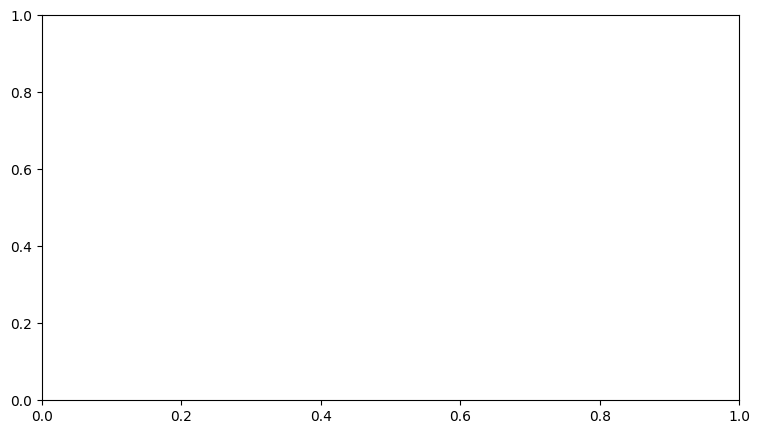

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, num_epochs + 1),
    resnet_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, num_epochs + 1),
    resnet_val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet18 Training History")
plt.xticks(range(1, num_epochs + 1))
plt.legend()
plt.grid(True)
plt.show()

plt.savefig("resnet18_training_history.png", dpi=300, bbox_inches="tight")

In [ ]:
import json

resnet_history = {
    "train_loss": resnet_train_losses,
    "val_loss": resnet_val_losses
}

with open("resnet18_training_history.json", "w") as f:
    json.dump(resnet_history, f, indent=4)

print("Training history saved!")

Training history saved!


In [ ]:

# Reset model with pretrained ResNet18 weights
resnet_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

original_conv = resnet_model.conv1

resnet_model.conv1 = nn.Conv2d(
    1, 64, kernel_size=7, stride=2, padding=3, bias=False
)

with torch.no_grad():
    resnet_model.conv1.weight.copy_(
        original_conv.weight.mean(dim=1, keepdim=True)
    )

resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features, 14
)

resnet_model = resnet_model.to(device)

# Loss and optimizer
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)

optimizer = optim.Adam(
    resnet_model.parameters(),
    lr=0.0001
)

# Training configuration
num_epochs = 5
best_val_loss = float("inf")

resnet_train_losses = []
resnet_val_losses = []

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        resnet_model, train_loader, criterion, optimizer, device
    )

    val_loss = validate_one_epoch(
        resnet_model, val_loader, criterion, device
    )

    resnet_train_losses.append(train_loss)
    resnet_val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            resnet_model.state_dict(),
            "resnet18_best.pth"
        )

        best_epoch = epoch + 1

        print("Best model saved!")

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

print("\nBest epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))


TypeError: cannot assign 'numpy.ndarray' object to buffer 'pos_weight' (torch Tensor or None required)

In [ ]:

# Load best checkpoint
resnet_model.load_state_dict(
    torch.load(
        "resnet18_best.pth",
        map_location=device,
        weights_only=True
    )
)

resnet_model.eval()

print("Best ResNet18 model loaded successfully!")


FileNotFoundError: [Errno 2] No such file or directory: 'resnet18_best.pth'

In [ ]:
import os

print("=== DATASET VARIABLES ===")

for name in ["train_dataset", "val_dataset", "test_dataset"]:
    if name in globals():
        dataset = globals()[name]
        print(f"\n{name}:")
        print("Type:", type(dataset))
        print("Length:", len(dataset))

        if hasattr(dataset, "labels"):
            print("Labels shape:", dataset.labels.shape)

print("\n=== MODEL VARIABLES ===")

for name in ["model", "device", "class_names"]:
    if name in globals():
        print(name, ":", type(globals()[name]))

print("\n=== CHECKPOINT FILES ===")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".pth") or file.endswith(".pt"):
            print(os.path.join(root, file))

=== DATASET VARIABLES ===

train_dataset:
Type: <class 'medmnist.dataset.ChestMNIST'>
Length: 78468
Labels shape: (78468, 14)

val_dataset:
Type: <class 'medmnist.dataset.ChestMNIST'>
Length: 11219
Labels shape: (11219, 14)

test_dataset:
Type: <class 'medmnist.dataset.ChestMNIST'>
Length: 22433
Labels shape: (22433, 14)

=== MODEL VARIABLES ===
device : <class 'torch.device'>
class_names : <class 'list'>

=== CHECKPOINT FILES ===


In [ ]:
import numpy as np

# Selected disease indices
selected_indices = [0, 1, 2, 3, 4, 7]

# New class names
selected_class_names = [
    "atelectasis",
    "cardiomegaly",
    "effusion",
    "infiltration",
    "mass",
    "pneumothorax"
]

# Extract only selected labels
train_labels_6 = train_dataset.labels[:, selected_indices].astype(np.float32)
val_labels_6 = val_dataset.labels[:, selected_indices].astype(np.float32)
test_labels_6 = test_dataset.labels[:, selected_indices].astype(np.float32)

print("Train labels:", train_labels_6.shape)
print("Validation labels:", val_labels_6.shape)
print("Test labels:", test_labels_6.shape)

print("\n=== CLASS DISTRIBUTION ===")

for i, name in enumerate(selected_class_names):
    positives = int(train_labels_6[:, i].sum())
    negatives = len(train_labels_6) - positives

    print(
        f"{name:15s} | "
        f"Positive: {positives:6d} | "
        f"Negative: {negatives:6d} | "
        f"Prevalence: {positives / len(train_labels_6):.2%}"
    )

Train labels: (78468, 6)
Validation labels: (11219, 6)
Test labels: (22433, 6)

=== CLASS DISTRIBUTION ===
atelectasis     | Positive:   7996 | Negative:  70472 | Prevalence: 10.19%
cardiomegaly    | Positive:   1950 | Negative:  76518 | Prevalence: 2.49%
effusion        | Positive:   9261 | Negative:  69207 | Prevalence: 11.80%
infiltration    | Positive:  13914 | Negative:  64554 | Prevalence: 17.73%
mass            | Positive:   3988 | Negative:  74480 | Prevalence: 5.08%
pneumothorax    | Positive:   3705 | Negative:  74763 | Prevalence: 4.72%


In [ ]:
import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader

# Dataset wrapper: returns only the selected 6 labels
class SelectedLabelsDataset(Dataset):
    def __init__(self, original_dataset, selected_indices):
        self.original_dataset = original_dataset
        self.selected_indices = selected_indices

    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, idx):
        image, labels = self.original_dataset[idx]

        labels = np.asarray(labels, dtype=np.float32)
        selected_labels = labels[self.selected_indices]

        selected_labels = torch.tensor(
            selected_labels,
            dtype=torch.float32
        )

        return image, selected_labels


# Create new datasets
train_dataset_6 = SelectedLabelsDataset(
    train_dataset, selected_indices
)

val_dataset_6 = SelectedLabelsDataset(
    val_dataset, selected_indices
)

test_dataset_6 = SelectedLabelsDataset(
    test_dataset, selected_indices
)


# DataLoaders
batch_size = 32

train_loader_6 = DataLoader(
    train_dataset_6,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_6 = DataLoader(
    val_dataset_6,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_6 = DataLoader(
    test_dataset_6,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# Verify the first batch
images, labels = next(iter(train_loader_6))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("\nImage dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("\nSelected classes:", selected_class_names)
print("Batch positive counts:", labels.sum(dim=0))

Images shape: torch.Size([32, 1, 128, 128])
Labels shape: torch.Size([32, 6])

Image dtype: torch.float32
Label dtype: torch.float32

Selected classes: ['atelectasis', 'cardiomegaly', 'effusion', 'infiltration', 'mass', 'pneumothorax']
Batch positive counts: tensor([4., 0., 4., 6., 3., 1.])


In [ ]:
import torch

checkpoint = torch.load(
    "/content/resnet18_best.pth",
    map_location=device,
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    print(list(checkpoint.keys())[:20])

    # Check whether the checkpoint is a state_dict
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint

    print("\nFirst parameter shapes:")

    for key, value in list(state_dict.items())[:8]:
        print(key, value.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/content/resnet18_best.pth'

In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# 1. Create a ResNet18 architecture
model_6 = models.resnet18(weights=None)

# 2. Adapt the first convolution layer for grayscale images
model_6.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)

# 3. Replace the final classification layer
model_6.fc = nn.Linear(
    in_features=512,
    out_features=6
)

# 4. Remove the old 14-class classification layer
state_dict_6 = {
    key: value
    for key, value in state_dict.items()
    if not key.startswith("fc.")
}

# 5. Load the pretrained 14-class model weights
load_result = model_6.load_state_dict(
    state_dict_6,
    strict=False
)

# 6. Move model to GPU
model_6 = model_6.to(device)

# 7. Enable training for all parameters
for param in model_6.parameters():
    param.requires_grad = True

print("=== MODEL CREATED ===")
print(model_6.fc)

print("\nMissing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

print("\nTotal parameters:",
      sum(p.numel() for p in model_6.parameters()))

print("Trainable parameters:",
      sum(p.numel() for p in model_6.parameters() if p.requires_grad))

# 8. Test model output
model_6.eval()

with torch.no_grad():
    sample_output = model_6(images.to(device))

print("\nInput shape:", images.shape)
print("Output shape:", sample_output.shape)

NameError: name 'state_dict' is not defined

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Calculate positive and negative samples
positive_counts = train_labels_6.sum(axis=0)
negative_counts = len(train_labels_6) - positive_counts

# 2. Calculate pos_weight
pos_weights = negative_counts / positive_counts

# Limit maximum weight to 50
pos_weights = np.clip(pos_weights, 1.0, 50.0)

pos_weights_tensor = torch.tensor(
    pos_weights,
    dtype=torch.float32
).to(device)

# 3. Define loss function
criterion_6 = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights_tensor
)

# 4. Define optimizer
optimizer_6 = optim.Adam(
    model_6.parameters(),
    lr=0.0001
)

# 5. Training configuration
num_epochs_6 = 5
best_val_loss_6 = float("inf")

print("=== TRAINING CONFIGURATION ===")

print("\nPositive weights:")
for name, weight in zip(selected_class_names, pos_weights):
    print(f"{name:15s}: {weight:.4f}")

print("\nLoss function:", criterion_6)
print("Optimizer:", optimizer_6)
print("Learning rate: 0.0001")
print("Epochs:", num_epochs_6)
print("Batch size:", batch_size)

=== TRAINING CONFIGURATION ===

Positive weights:
atelectasis    : 8.8134
cardiomegaly   : 39.2400
effusion       : 7.4730
infiltration   : 4.6395
mass           : 18.6760
pneumothorax   : 20.1789

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.0001
Epochs: 5
Batch size: 32


In [ ]:
import torch
import copy
import time

# Training history
train_losses_6 = []
val_losses_6 = []

best_val_loss_6 = float("inf")
best_epoch_6 = 0

start_time = time.time()

for epoch in range(num_epochs_6):

    # =========================
    # TRAINING
    # =========================
    model_6.train()
    running_train_loss = 0.0

    for images, labels in train_loader_6:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_6.zero_grad()

        outputs = model_6(images)
        loss = criterion_6(outputs, labels)

        loss.backward()
        optimizer_6.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset_6)

    # =========================
    # VALIDATION
    # =========================
    model_6.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader_6:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_6(images)
            loss = criterion_6(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset_6)

    train_losses_6.append(epoch_train_loss)
    val_losses_6.append(epoch_val_loss)

    print(
        f"Epoch [{epoch + 1}/{num_epochs_6}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Val Loss: {epoch_val_loss:.4f}"
    )

    # =========================
    # SAVE BEST MODEL
    # =========================
    if epoch_val_loss < best_val_loss_6:

        best_val_loss_6 = epoch_val_loss
        best_epoch_6 = epoch + 1

        torch.save(
            {
                "model_state_dict": copy.deepcopy(model_6.state_dict()),
                "class_names": selected_class_names,
                "selected_indices": selected_indices,
                "epoch": best_epoch_6,
                "best_val_loss": best_val_loss_6
            },
            "/content/resnet18_6class_best.pth"
        )

        print("Best model saved!")

elapsed_time = (time.time() - start_time) / 60

print("\n=== TRAINING COMPLETED ===")
print(f"Best epoch: {best_epoch_6}")
print(f"Best validation loss: {best_val_loss_6:.4f}")
print(f"Training time: {elapsed_time:.2f} minutes")
print("Model saved: resnet18_6class_best.pth")

RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same

In [ ]:
checkpoint_6 = torch.load(
    "/content/resnet18_6class_best.pth",
    map_location=device,
    weights_only=False
)

model_6.load_state_dict(checkpoint_6["model_state_dict"])
model_6.eval()

print("Best model loaded!")
print("Best epoch:", checkpoint_6["epoch"])
print("Best validation loss:", checkpoint_6["best_val_loss"])

FileNotFoundError: [Errno 2] No such file or directory: '/content/resnet18_6class_best.pth'

In [ ]:
import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'medical_image_ai_6class', 'sample_data']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving chestmnist_evaluation.py to chestmnist_evaluation.py


In [ ]:
import sys
sys.path.append("/content")

from chestmnist_evaluation import (
    collect_logits,
    evaluate_probabilities,
    find_best_thresholds,
    crossfit_threshold_evaluation
)

print("Evaluation module imported successfully!")

Evaluation module imported successfully!


In [ ]:
val_logits_6, val_targets_6 = collect_logits(
    model_6,
    val_loader_6,
    device
)

val_probs_6 = 1 / (
    1 + np.exp(-np.clip(val_logits_6, -50, 50))
)

print("Logits shape:", val_logits_6.shape)
print("Targets shape:", val_targets_6.shape)
print("Probabilities shape:", val_probs_6.shape)

RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same

In [ ]:
metrics_6 = evaluate_probabilities(
    val_targets_6,
    val_probs_6,
    thresholds=0.5,
    label_names=selected_class_names
)

print("=== 6-Class ResNet18 Validation Results ===")
print(f"Macro AUROC: {metrics_6['macro_auroc']:.4f}")
print(f"Mean Average Precision: {metrics_6['mean_average_precision']:.4f}")
print(f"Micro F1: {metrics_6['micro_f1']:.4f}")
print(f"Macro F1: {metrics_6['macro_f1']:.4f}")
print(f"Weighted F1: {metrics_6['weighted_f1']:.4f}")

per_class_df_6 = pd.DataFrame(metrics_6["per_class"])

display(
    per_class_df_6[
        ["label", "precision", "recall", "f1", "support",
         "auroc", "average_precision"]
    ].sort_values("f1", ascending=False).reset_index(drop=True)
)

NameError: name 'val_targets_6' is not defined

In [ ]:
import pandas as pd

per_class_df_6 = pd.DataFrame(metrics_6["per_class"])

display(
    per_class_df_6[
        ["label", "precision", "recall", "f1", "support",
         "auroc", "average_precision"]
    ].sort_values(
        "f1", ascending=False
    ).reset_index(drop=True)
)

,label,precision,recall,f1,support,auroc,average_precision
0,effusion,0.315082,0.761610,0.445753,1292,0.851954,0.439818
1,infiltration,0.278809,0.543112,0.368465,2018,0.665279,0.314119
2,atelectasis,0.197424,0.753351,0.312860,1119,0.773285,0.266351
3,pneumothorax,0.153533,0.672619,0.250000,504,0.820041,0.226390
4,mass,0.121143,0.760000,0.208975,625,0.790798,0.212991
5,cardiomegaly,0.069341,0.850000,0.128221,240,0.886804,0.225850


In [ ]:
best_thresholds_6, threshold_results_6 = find_best_thresholds(
    val_targets_6,
    val_probs_6,
    label_names=selected_class_names
)

threshold_df_6 = pd.DataFrame(threshold_results_6)

display(threshold_df_6)

,label,threshold,best_f1_on_fit_data,status
0,atelectasis,0.65,0.347205,ok
1,cardiomegaly,0.95,0.314530,ok
2,effusion,0.65,0.478390,ok
3,infiltration,0.55,0.369382,ok
4,mass,0.75,0.290665,ok
5,pneumothorax,0.70,0.304853,ok


In [ ]:
crossfit_results_6 = crossfit_threshold_evaluation(
    val_targets_6,
    val_probs_6,
    n_splits=2,
    random_state=42,
    label_names=selected_class_names
)

print("=== 6-Class ResNet18 Cross-Fitted Evaluation ===")
print(crossfit_results_6)

=== 6-Class ResNet18 Cross-Fitted Evaluation ===
{'method': 'KFold cross-fitted per-class thresholds', 'n_splits': 2, 'random_state': 42, 'fold_thresholds': [[0.6500000000000001, 0.9500000000000001, 0.7000000000000001, 0.55, 0.7500000000000001, 0.7500000000000001], [0.6500000000000001, 0.9500000000000001, 0.6500000000000001, 0.5, 0.7500000000000001, 0.7000000000000001]], 'metrics': {'n_samples': 11219, 'n_labels': 6, 'micro_precision': 0.2932048681541582, 'micro_recall': 0.4986202138668506, 'micro_f1': 0.36926810576063357, 'macro_precision': 0.2812117178456794, 'macro_recall': 0.4653334233001057, 'macro_f1': 0.34968080810172536, 'weighted_precision': 0.29724135410987296, 'weighted_recall': 0.4986202138668506, 'weighted_f1': 0.3716726201885221, 'macro_auroc': 0.7980268668353027, 'mean_average_precision': 0.28091986339093505, 'per_class': [{'label': 'atelectasis', 'precision': 0.2660637791527844, 'recall': 0.49955317247542447, 'f1': 0.34720496894409936, 'support': 1119, 'prevalence': 0.0

In [ ]:
# Original 14-class ResNet18 model
model_14 = models.resnet18(weights=None)

model_14.conv1 = nn.Conv2d(
    1, 64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)

model_14.fc = nn.Linear(512, 14)

# Load original checkpoint
old_state_dict = torch.load(
    "/content/resnet18_best.pth",
    map_location=device,
    weights_only=True
)

if "model_state_dict" in old_state_dict:
    old_state_dict = old_state_dict["model_state_dict"]

model_14.load_state_dict(old_state_dict)
model_14 = model_14.to(device)
model_14.eval()

# Original validation DataLoader (14 labels)
val_loader_14 = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Collect predictions
old_logits_14, old_targets_14 = collect_logits(
    model_14,
    val_loader_14,
    device
)

old_probs_14 = 1 / (
    1 + np.exp(-np.clip(old_logits_14, -50, 50))
)

# Select the same six classes
old_probs_6 = old_probs_14[:, selected_indices]
old_targets_6 = old_targets_14[:, selected_indices]

print("Old model predictions:", old_probs_6.shape)
print("Old model targets:", old_targets_6.shape)

assert np.array_equal(old_targets_6, val_targets_6)

print("Validation targets match!")

Old model predictions: (11219, 6)
Old model targets: (11219, 6)
Validation targets match!


In [ ]:
# Old 14-class model: selected six classes
old_metrics_6 = evaluate_probabilities(
    old_targets_6,
    old_probs_6,
    thresholds=0.5,
    label_names=selected_class_names
)

# New 6-class model: fixed 0.5 threshold
new_metrics_6 = evaluate_probabilities(
    val_targets_6,
    val_probs_6,
    thresholds=0.5,
    label_names=selected_class_names
)

comparison_df = pd.DataFrame({
    "Metric": [
        "Micro F1",
        "Macro F1",
        "Weighted F1",
        "Macro AUROC",
        "Mean Average Precision"
    ],
    "Old ResNet18 (14 classes)": [
        old_metrics_6["micro_f1"],
        old_metrics_6["macro_f1"],
        old_metrics_6["weighted_f1"],
        old_metrics_6["macro_auroc"],
        old_metrics_6["mean_average_precision"]
    ],
    "New ResNet18 (6 classes)": [
        new_metrics_6["micro_f1"],
        new_metrics_6["macro_f1"],
        new_metrics_6["weighted_f1"],
        new_metrics_6["macro_auroc"],
        new_metrics_6["mean_average_precision"]
    ]
})

comparison_df["Difference"] = (
    comparison_df["New ResNet18 (6 classes)"]
    - comparison_df["Old ResNet18 (14 classes)"]
)

display(comparison_df.round(4))

old_per_class = pd.DataFrame(old_metrics_6["per_class"])
new_per_class = pd.DataFrame(new_metrics_6["per_class"])

class_comparison = pd.DataFrame({
    "Class": selected_class_names,
    "Old F1": old_per_class["f1"].values,
    "New F1": new_per_class["f1"].values,
    "Old AUROC": old_per_class["auroc"].values,
    "New AUROC": new_per_class["auroc"].values
})

class_comparison["F1 Difference"] = (
    class_comparison["New F1"] - class_comparison["Old F1"]
)

display(class_comparison.round(4))

,Metric,Old ResNet18 (14 classes),New ResNet18 (6 classes),Difference
0,Micro F1,0.2861,0.3009,0.0148
1,Macro F1,0.2666,0.2857,0.0191
2,Weighted F1,0.3184,0.3375,0.0192
3,Macro AUROC,0.7878,0.7980,0.0102
4,Mean Average Precision,0.2634,0.2809,0.0175


,Class,Old F1,New F1,Old AUROC,New AUROC,F1 Difference
0,atelectasis,0.3002,0.3129,0.7601,0.7733,0.0126
1,cardiomegaly,0.1036,0.1282,0.8783,0.8868,0.0246
2,effusion,0.3851,0.4458,0.8375,0.8520,0.0607
3,infiltration,0.3634,0.3685,0.6679,0.6653,0.0051
4,mass,0.2367,0.2090,0.7721,0.7908,-0.0277
5,pneumothorax,0.2107,0.2500,0.8109,0.8200,0.0393


In [ ]:
import torch
import os

save_dir = "/content/medical_image_ai_6class"
os.makedirs(save_dir, exist_ok=True)

checkpoint_path = os.path.join(
    save_dir,
    "resnet18_6class_best.pth"
)

torch.save(
    {
        "model_state_dict": model_6.state_dict(),
        "class_names": selected_class_names,
        "selected_indices": selected_indices,
        "input_size": 128,
        "architecture": "ResNet18",
        "num_classes": 6,
        "best_epoch": best_epoch_6,
        "best_val_loss": best_val_loss_6,
        "optimizer": "Adam",
        "learning_rate": 0.0001,
        "batch_size": 32
    },
    checkpoint_path
)

print("Model saved:", checkpoint_path)
print("File size:", round(os.path.getsize(checkpoint_path) / (1024**2), 2), "MB")

Model saved: /content/medical_image_ai_6class/resnet18_6class_best.pth
File size: 42.7 MB


In [ ]:
import os

checkpoint_path = "/content/resnet18_6class_best.pth"

if os.path.exists(checkpoint_path):
    print("Checkpoint bulundu!")
    print("File size:", round(os.path.getsize(checkpoint_path) / (1024**2), 2), "MB")
else:
    print("Checkpoint bulunamadı!")

Checkpoint bulunamadı!
